Load the model and reconstruct datasets

In [1]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

PROJECT_DIR = Path(
    r"d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics"
)

PROCESSED_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "credit_risk_modeling_cohort.csv.gz"
)

MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "logistic_regression_baseline.joblib"
)

assert PROCESSED_PATH.exists()
assert MODEL_PATH.exists()

print("Paths verified!")

Paths verified!


In [2]:
# load saved model and dataset

# Load fitted pipeline and metadata
model_artifact = joblib.load(MODEL_PATH)

log_reg_pipeline = model_artifact["pipeline"]

MODEL_FEATURES = model_artifact["model_features"]
NUMERIC_FEATURES = model_artifact["numeric_features"]
CATEGORICAL_FEATURES = model_artifact["categorical_features"]

TARGET = model_artifact["target"]
SELECTED_THRESHOLD = model_artifact["threshold"]

# Load processed dataset
model_df = pd.read_csv(
    PROCESSED_PATH,
    compression="gzip",
    low_memory=False
)

model_df["term"] = (
    model_df["term"]
    .astype("string")
    .str.strip()
)

model_df["issue_year"] = pd.to_numeric(
    model_df["issue_year"],
    errors="coerce"
)

model_df[TARGET] = model_df[TARGET].astype(int)

# Reconstruct exactly the same 36-month population
model_36m = model_df[
    model_df["term"] == "36 months"
].copy()

train_df = model_36m[
    model_36m["issue_year"] <= 2013
].copy()

val_df = model_36m[
    model_36m["issue_year"] == 2014
].copy()

test_df = model_36m[
    model_36m["issue_year"] == 2015
].copy()

# Feature matrices and targets
X_train = train_df[MODEL_FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[MODEL_FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[MODEL_FEATURES].copy()
y_test = test_df[TARGET].copy()

print("Model loaded:", type(log_reg_pipeline).__name__)
print("Selected threshold:", SELECTED_THRESHOLD)

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

assert len(X_train) == 172988
assert len(X_val) == 162570
assert len(X_test) == 282787

print("\nAll datasets reconstructed successfully.")

Model loaded: Pipeline
Selected threshold: 0.15

Training: (172988, 15)
Validation: (162570, 15)
Test: (282787, 15)

All datasets reconstructed successfully.


In [3]:
train_proba = log_reg_pipeline.predict_proba(X_train)[:, 1]
val_proba = log_reg_pipeline.predict_proba(X_val)[:, 1]
test_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

print("Training predictions generated:", len(train_proba))
print("Validation predictions generated:", len(val_proba))
print("Test predictions generated:", len(test_proba))

d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Training predictions generated: 172988
Validation predictions generated: 162570
Test predictions generated: 282787


d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


<!-- reproduce final performance -->

In [4]:
def evaluate_model(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    fpr, tpr, _ = roc_curve(
        y_true,
        probabilities
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    ks = np.max(tpr - fpr)

    return {
        "ROC-AUC": roc_auc,
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
        "KS": ks,
        "Gini": 2 * roc_auc - 1,
        "Log Loss": log_loss(y_true, probabilities),
        "Brier Score": brier_score_loss(
            y_true, probabilities
        ),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        )
    }

In [5]:
validation_metrics = evaluate_model(
    y_val,
    val_proba,
    SELECTED_THRESHOLD
)

test_metrics = evaluate_model(
    y_test,
    test_proba,
    SELECTED_THRESHOLD
)

performance_df = pd.DataFrame({
    "Validation 2014": validation_metrics,
    "Out-of-Time Test 2015": test_metrics
})

display(performance_df.round(4))

,Validation 2014,Out-of-Time Test 2015
ROC-AUC,0.6494,0.6530
Average Precision,0.2148,0.2349
KS,0.2198,0.2208
Gini,0.2988,0.3060
Log Loss,0.3842,0.4046
Brier Score,0.1146,0.1225
Precision,0.2100,0.2293
Recall,0.5202,0.4994
F1 Score,0.2992,0.3143


In [6]:
# caliberation stability

calibration_summary = pd.DataFrame({
    "Period": ["Validation 2014", "Test 2015"],
    "Actual Default Rate": [
        y_val.mean(),
        y_test.mean()
    ],
    "Mean Predicted Probability": [
        val_proba.mean(),
        test_proba.mean()
    ]
})

calibration_summary["Difference"] = (
    calibration_summary["Actual Default Rate"]
    - calibration_summary["Mean Predicted Probability"]
)

display(
    calibration_summary.style.format({
        "Actual Default Rate": "{:.2%}",
        "Mean Predicted Probability": "{:.2%}",
        "Difference": "{:.2%}"
    })
)

,Period,Actual Default Rate,Mean Predicted Probability,Difference
0,Validation 2014,13.73%,13.17%,0.56%
1,Test 2015,14.88%,12.88%,2.00%


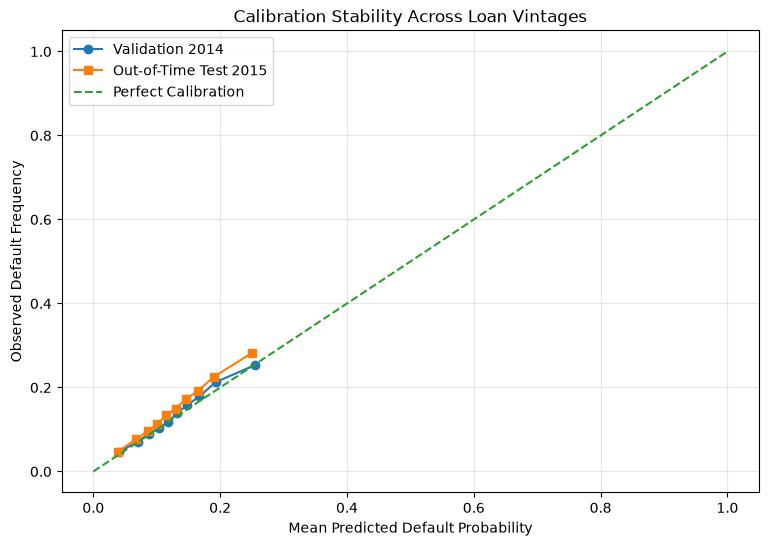

In [7]:
val_fraction, val_mean = calibration_curve(
    y_val,
    val_proba,
    n_bins=10,
    strategy="quantile"
)

test_fraction, test_mean = calibration_curve(
    y_test,
    test_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(9, 6))

plt.plot(
    val_mean,
    val_fraction,
    marker="o",
    label="Validation 2014"
)

plt.plot(
    test_mean,
    test_fraction,
    marker="s",
    label="Out-of-Time Test 2015"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Frequency")
plt.title("Calibration Stability Across Loan Vintages")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Understanding population stability index

Have you ever wondered how we would know that a model, which was working reasonably well when deployed, is starting to become unsuitable six months or a year later?

One possibility is that the population being evaluated has changed.

For example:
- Borrowers now have substantially different income distributions.
- Average credit scores have shifted.
- Loan amounts are increasing.
- The model's predicted risk-score distribution has changed.
This is called population drift or population distribution shift, depending on the context.

What exactly is PSI?
The Population Stability Index measures the change in the distribution of a variable between a reference population and a comparison population.

How PSI is calculated
Step 1: Define fixed buckets using the reference population.


Step 2: Calculate the percentage of observations in every bucket for both populations.


Step 3: Calculate the PSI contribution of each bucket.


Step 4: Sum all contributions to get PSI.

PSI	Typical interpretation
Below 0.10	Little distribution change
0.10–0.25	Moderate change; investigate
Above 0.25	Significant change; investigate closely



In [8]:
def calculate_numeric_psi(reference, current, bins=10, epsilon=1e-6):

    reference = pd.to_numeric(
        reference, errors="coerce"
    )

    current = pd.to_numeric(
        current, errors="coerce"
    )

    reference_nonmissing = reference.dropna()

    # Establish bucket edges using reference data
    quantiles = np.linspace(0, 1, bins + 1)

    edges = np.unique(
        np.quantile(
            reference_nonmissing,
            quantiles
        )
    )

    # Handle features with insufficient unique values
    if len(edges) < 2:
        edges = np.array([-np.inf, np.inf])
    else:
        edges[0] = -np.inf
        edges[-1] = np.inf

    # Assign observations to fixed reference buckets
    reference_buckets = pd.Series(
        pd.cut(
            reference,
            bins=edges,
            include_lowest=True
        ).astype("object"),
        index=reference.index
    )

    current_buckets = pd.Series(
        pd.cut(
            current,
            bins=edges,
            include_lowest=True
        ).astype("object"),
        index=current.index
    )

    # Preserve missing values as their own bucket
    reference_buckets = (
        reference_buckets
        .where(reference.notna(), "MISSING")
        .astype(str)
    )

    current_buckets = (
        current_buckets
        .where(current.notna(), "MISSING")
        .astype(str)
    )

    # Align bucket categories
    all_buckets = sorted(
        set(reference_buckets.unique())
        | set(current_buckets.unique())
    )

    reference_pct = (
        reference_buckets
        .value_counts(normalize=True)
        .reindex(all_buckets, fill_value=0)
    )

    current_pct = (
        current_buckets
        .value_counts(normalize=True)
        .reindex(all_buckets, fill_value=0)
    )

    # Small epsilon prevents log(0)
    reference_pct = reference_pct.clip(lower=epsilon)
    current_pct = current_pct.clip(lower=epsilon)

    # Renormalize after smoothing
    reference_pct = reference_pct / reference_pct.sum()
    current_pct = current_pct / current_pct.sum()

    psi = (
        (current_pct - reference_pct)
        * np.log(current_pct / reference_pct)
    ).sum()

    return float(psi)

In [10]:
def calculate_categorical_psi(
    reference,
    current,
    epsilon=1e-6
):

    reference = (
        reference
        .astype("string")
        .fillna("MISSING")
        .astype(str)
    )

    current = (
        current
        .astype("string")
        .fillna("MISSING")
        .astype(str)
    )

    all_categories = sorted(
        set(reference.unique())
        | set(current.unique())
    )

    reference_pct = (
        reference
        .value_counts(normalize=True)
        .reindex(all_categories, fill_value=0)
    )

    current_pct = (
        current
        .value_counts(normalize=True)
        .reindex(all_categories, fill_value=0)
    )

    reference_pct = reference_pct.clip(lower=epsilon)
    current_pct = current_pct.clip(lower=epsilon)

    reference_pct = reference_pct / reference_pct.sum()
    current_pct = current_pct / current_pct.sum()

    psi = (
        (current_pct - reference_pct)
        * np.log(current_pct / reference_pct)
    ).sum()

    return float(psi)

In [11]:
NUMERIC_TO_MONITOR = [
    "annual_inc",
    "dti",
    "fico_range_low",
    "loan_amnt",
    "revol_util",
    "revol_bal"
]

CATEGORICAL_TO_MONITOR = [
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose"
]

psi_results = []

# Numerical feature PSI
for feature in NUMERIC_TO_MONITOR:

    val_psi = calculate_numeric_psi(
        X_train[feature],
        X_val[feature]
    )

    test_psi = calculate_numeric_psi(
        X_train[feature],
        X_test[feature]
    )

    psi_results.append({
        "feature": feature,
        "type": "Numerical",
        "PSI - Validation": val_psi,
        "PSI - Test": test_psi
    })


# Categorical feature PSI
for feature in CATEGORICAL_TO_MONITOR:

    val_psi = calculate_categorical_psi(
        X_train[feature],
        X_val[feature]
    )

    test_psi = calculate_categorical_psi(
        X_train[feature],
        X_test[feature]
    )

    psi_results.append({
        "feature": feature,
        "type": "Categorical",
        "PSI - Validation": val_psi,
        "PSI - Test": test_psi
    })


psi_df = pd.DataFrame(psi_results)

display(
    psi_df.sort_values(
        "PSI - Test",
        ascending=False
    ).round(4)
)

,feature,type,PSI - Validation,PSI - Test
8,verification_status,Categorical,0.1226,0.1970
9,purpose,Categorical,0.0927,0.1063
1,dti,Numerical,0.0347,0.0841
2,fico_range_low,Numerical,0.0734,0.0559
4,revol_util,Numerical,0.0248,0.0367
6,emp_length,Categorical,0.0186,0.0332
3,loan_amnt,Numerical,0.0139,0.0229
7,home_ownership,Categorical,0.0102,0.0154
5,revol_bal,Numerical,0.0091,0.0111
0,annual_inc,Numerical,0.0050,0.0106


In [12]:
score_psi_val = calculate_numeric_psi(
    pd.Series(train_proba),
    pd.Series(val_proba)
)

score_psi_test = calculate_numeric_psi(
    pd.Series(train_proba),
    pd.Series(test_proba)
)

print("MODEL SCORE PSI")
print("-" * 35)

print(f"Training vs Validation PSI: {score_psi_val:.4f}")
print(f"Training vs Test PSI:       {score_psi_test:.4f}")

MODEL SCORE PSI
-----------------------------------
Training vs Validation PSI: 0.0150
Training vs Test PSI:       0.0063



# Final Model Validation Summary

## 1. Model Overview

An L2-regularized Logistic Regression model was developed to predict adverse loan outcomes using historical LendingClub loan data.

The model uses 15 borrower and loan characteristics, with preprocessing performed through a Scikit-learn Pipeline.

## 2. Validation Design

A chronological evaluation strategy was used:

- Training: 2007–2013
- Validation: 2014
- Out-of-time test: 2015

The 2015 cohort was kept separate during model development and threshold selection.

## 3. Performance Assessment

The model achieved an out-of-time ROC-AUC of 0.6530, KS of 0.2208 and Gini of 0.3060.

Discriminatory performance remained relatively stable between validation and test periods.

At the selected 0.15 threshold, test precision was 22.93%, recall was 49.94% and F1 was 0.3143.

## 4. Calibration Assessment

The model's mean predicted default probability was 13.17% on the validation cohort, compared with an observed default rate of 13.73%.

On the test cohort, mean predicted probability was 12.88%, compared with an observed default rate of 14.88%.

This indicates aggregate underestimation of risk in the later cohort and motivates continued calibration monitoring.

## 5. Population Stability

PSI was calculated for selected numerical features, categorical features and model scores.

The training cohort was used as the reference population. Validation and test distributions were compared against it.

PSI values should be interpreted as distribution-shift indicators, not direct measures of model accuracy or predictive deterioration.

## 6. Key Limitations

- The project uses LendingClub peer-to-peer lending data rather than bank-originated portfolio data.
- Charged-off status is an outcome proxy, not a confirmed regulatory default definition.
- Accepted-loan selection and maturity filtering introduce potential biases.
- The baseline is restricted to 36-month loans.
- The model demonstrates modest discrimination and should not be treated as deployment-ready.
- Statistical significance testing, comprehensive backtesting, formal model approval and production monitoring have not been completed.

## 7. Recommended Monitoring

A production model would require:

- Ongoing input-variable and missingness monitoring.
- Monitoring of categorical values and unseen categories.
- Periodic PSI analysis of feature and score distributions.
- Vintage-based outcome performance monitoring.
- ROC-AUC, KS, Gini, precision and recall tracking.
- Calibration and Brier score monitoring.
- Formal review of performance deterioration and recalibration requirements.
- Documented model changes and independent validation.



## Population Stability Analysis — Findings

### Methodology

Population Stability Index (PSI) was calculated by comparing the training population (2007–2013) with the 2014 validation and 2015 out-of-time test populations.

For numerical features, reference buckets were defined using training-set quantiles. Categorical variables were compared using their observed category distributions.

The analysis covered ten selected borrower and loan characteristics and the model's predicted probability distribution.

### Feature-Level Results

The largest feature-level shift was observed in:

- Verification status: Test PSI = 0.1970
- Loan purpose: Test PSI = 0.1063

These indicate moderate distribution changes under commonly used PSI heuristics.

The remaining monitored features had PSI values below 0.10.

### Model Score Stability

- Training vs Validation score PSI: 0.0150
- Training vs Test score PSI: 0.0063

The overall predicted score distribution remained relatively stable across the observed origination periods.

### Interpretation

Despite low model-score PSI, the model exhibited aggregate probability underestimation in the 2015 cohort.

The actual default rate was 14.88%, compared with a mean predicted default probability of 12.88%.

This suggests that score-distribution stability does not necessarily imply calibration stability or stable outcome relationships.

The results motivate additional calibration monitoring and investigation of changes in underwriting practices, borrower composition and other potential sources of temporal drift.

### Limitations

PSI is a distribution-comparison statistic and does not independently establish model deterioration.

The thresholds used for interpretation are common heuristics rather than universal regulatory acceptance criteria.

Only selected features were monitored. The analysis does not constitute a comprehensive production monitoring framework.
